# Forward model: (metallicity, reddening, age) → ridgelines

The reverse of `ridgeline_metallicity_regression.ipynb`. Instead of predicting [Fe/H] from ridges, predict the ridges from cluster properties.

**Idea in plain terms**
1. A cluster's ridges (10 colors × a handful of magnitude bins) are a long vector of numbers, but they are smooth and strongly correlated, so they have only a few independent "shapes" (PCA components).
2. Compress each cluster's ridge vector to `k` PCA scores (k ≈ 2–4).
3. Learn a simple smooth function from the cluster properties to those `k` scores.
4. To get any ridge: scores → un-compress with PCA → every color at every bin.

**Why reddening is an input.** The observed colors are *not* dereddened, and the UV colors are very sensitive to dust. [Fe/H] alone leaves most of the cluster-to-cluster variation unexplained; adding E(B−V) (Harris 2010) fixes that. Age (Kruijssen) is tested on the subset of clusters that have it.

Everything is checked leave-one-cluster-out (PCA is refit inside every fold). Finally we **invert** the forward model to estimate [Fe/H] from an observed ridge (with E(B−V) known) and compare against direct regression.

In [5]:
import os, re, io, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_predict

sns.set_theme(style='whitegrid', context='notebook')

PROJECT_DIR = Path().resolve()
PROJECT_ROOT_NAME = 'spectroscopy-regression'
while PROJECT_DIR.name != PROJECT_ROOT_NAME and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)

K_MAX = 6          # max PCA components to try
GRID = np.arange(-0.75, 1.01, 0.25)   # F814W_abs bins covered by (almost) every cluster
PROJECT_DIR

WindowsPath('C:/Users/phucl/Research/gc/spectroscopy-regression')

## Data: ridge vectors, [Fe/H], age

In [6]:
labels = pd.read_csv('data/GC_metallicity_harris.csv').set_index('NGC')['Fe/H_harris']
ebv_all = pd.read_csv('data/GC_reddening_harris.csv').set_index('NGC')['EBV']

ridges = {}
with zipfile.ZipFile('data/GC Ridgelines.zip') as zf:
    for name in zf.namelist():
        m = re.search(r'NGC(\d+)_F814W_ridge\.csv$', name)
        if not m:
            continue
        d = pd.read_csv(io.BytesIO(zf.read(name)))
        d = d[d['low_conf'].astype(str) == 'False'].drop(columns='low_conf').dropna()
        if len(d) >= 2:
            ridges[int(m.group(1))] = d.sort_values('F814W_abs')

COLORS = [c for c in next(iter(ridges.values())).columns if '-' in c]

def ridge_vector(d):
    x = d['F814W_abs'].to_numpy()
    if GRID.min() < x.min() or GRID.max() > x.max():
        return None
    return np.concatenate([np.interp(GRID, x, d[c].to_numpy()) for c in COLORS])

vecs = {n: ridge_vector(d) for n, d in ridges.items()}
dropped = [n for n, v in vecs.items() if v is None]
print('clusters not covering the whole grid (dropped):', dropped)
Y = pd.DataFrame({n: v for n, v in vecs.items() if v is not None}).T
cols = pd.MultiIndex.from_product([COLORS, GRID], names=['color', 'F814W_abs'])
Y.columns = cols
feh = labels.loc[Y.index]
ebv = ebv_all.loc[Y.index]

ages = (pd.read_csv('data/NGC_combi.csv').rename(columns=str.strip)
        .assign(NGC=lambda d: pd.to_numeric(d['NGC'].astype(str).str.strip(), errors='coerce'))
        .groupby('NGC')['age_Kruijssen'].median())
age = ages.reindex(Y.index)
print('corr([Fe/H], E(B-V)) =', round(np.corrcoef(feh, ebv)[0, 1], 2))
print(f'{len(Y)} clusters x {Y.shape[1]} ridge values; age known for {age.notna().sum()} of them')

clusters not covering the whole grid (dropped): []
corr([Fe/H], E(B-V)) = 0.46
54 clusters x 80 ridge values; age known for 25 of them


## 1. Do ridges really have only a few degrees of freedom — and what drives them?

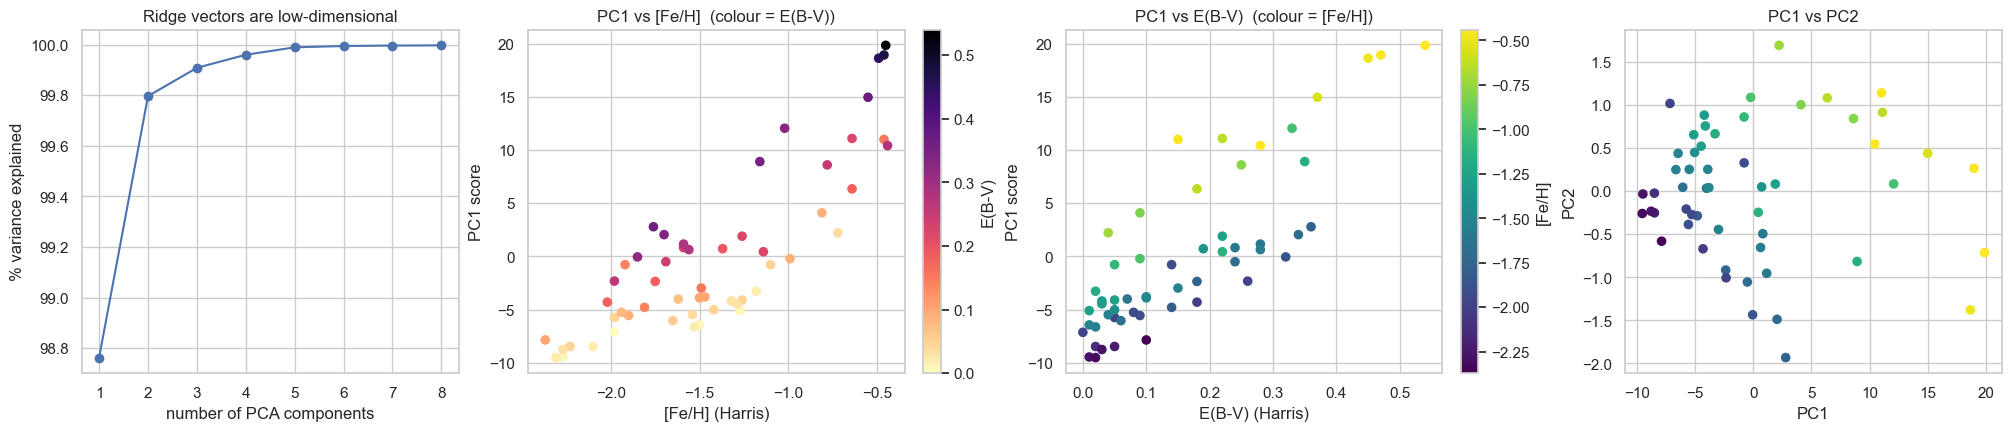

PC1: 98.76% var | corr with [Fe/H] +0.83 | corr with E(B-V) +0.83
PC2:  1.03% var | corr with [Fe/H] +0.43 | corr with E(B-V) -0.51
PC3:  0.11% var | corr with [Fe/H] +0.06 | corr with E(B-V) +0.06


In [7]:
pca = PCA().fit(Y.to_numpy())
cum = np.cumsum(pca.explained_variance_ratio_)
scores = pca.transform(Y.to_numpy())

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), constrained_layout=True)
axes[0].plot(range(1, 9), cum[:8] * 100, marker='o')
axes[0].set_xlabel('number of PCA components'); axes[0].set_ylabel('% variance explained')
axes[0].set_title('Ridge vectors are low-dimensional')
sc = axes[1].scatter(feh, scores[:, 0], c=ebv, cmap='magma_r', s=35)
axes[1].set_xlabel('[Fe/H] (Harris)'); axes[1].set_ylabel('PC1 score'); axes[1].set_title('PC1 vs [Fe/H]  (colour = E(B-V))')
fig.colorbar(sc, ax=axes[1], label='E(B-V)')
sc = axes[2].scatter(ebv, scores[:, 0], c=feh, cmap='viridis', s=35)
axes[2].set_xlabel('E(B-V) (Harris)'); axes[2].set_ylabel('PC1 score'); axes[2].set_title('PC1 vs E(B-V)  (colour = [Fe/H])')
fig.colorbar(sc, ax=axes[2], label='[Fe/H]')
sc = axes[3].scatter(scores[:, 0], scores[:, 1], c=feh, cmap='viridis', s=35)
axes[3].set_xlabel('PC1'); axes[3].set_ylabel('PC2'); axes[3].set_title('PC1 vs PC2')
plt.show()
for j in range(3):
    print(f'PC{j+1}: {pca.explained_variance_ratio_[j]*100:5.2f}% var | corr with [Fe/H] {np.corrcoef(scores[:, j], feh)[0,1]:+.2f} | corr with E(B-V) {np.corrcoef(scores[:, j], ebv)[0,1]:+.2f}')

## 2. The forward model

`ForwardModel(k, deg)`: PCA(k) on the ridge vectors, then a polynomial regression from the input columns to the `k` scores. `k=None` skips PCA ("a function per ridge value"). Inputs are standardised internally.

In [8]:
class ForwardModel:
    def __init__(self, k=3, deg=2):
        self.k, self.deg = k, deg

    def fit(self, X, Y):
        self.scaler = StandardScaler().fit(X)
        Z = Y
        if self.k is not None:
            self.pca = PCA(n_components=self.k).fit(Y)
            Z = self.pca.transform(Y)
        self.reg = make_pipeline(PolynomialFeatures(self.deg), LinearRegression()).fit(self.scaler.transform(X), Z)
        return self

    def predict(self, X):
        Z = self.reg.predict(self.scaler.transform(X))
        return Z if self.k is None else self.pca.inverse_transform(Z)


def loo_forward(make, X, Y):
    P = np.zeros_like(Y, dtype=float)
    idx = np.arange(len(Y))
    for i in idx:
        tr = idx != i
        P[i] = make().fit(X[tr], Y[tr]).predict(X[[i]])[0]
    return P

rmse = lambda P, Y: np.sqrt(np.mean((P - Y) ** 2))
Yv = Y.to_numpy()
INPUTS = {'[Fe/H]': np.c_[feh.to_numpy()],
          'E(B-V)': np.c_[ebv.to_numpy()],
          '[Fe/H] + E(B-V)': np.c_[feh.to_numpy(), ebv.to_numpy()]}
baseline = np.array([Yv[np.arange(len(Yv)) != i].mean(0) for i in range(len(Yv))])
rows = [dict(inputs='-', model='mean ridge (no model)', RMSE_mag=rmse(baseline, Yv))]
loo_preds = {}
for iname, X in INPUTS.items():
    for k in [None, 2, 3, 4]:
        for deg in [1, 2, 3]:
            P = loo_forward(lambda: ForwardModel(k, deg), X, Yv)
            name = f'{"per-bin" if k is None else f"PCA{k}"} + poly{deg}'
            rows.append(dict(inputs=iname, model=name, RMSE_mag=rmse(P, Yv)))
            loo_preds[(iname, name)] = P
res = pd.DataFrame(rows)
print('best per input set (leave-one-cluster-out RMSE of ridge colors, mag):')
res.loc[res.groupby('inputs').RMSE_mag.idxmin()].set_index('inputs').round(3)

best per input set (leave-one-cluster-out RMSE of ridge colors, mag):


,model,RMSE_mag
inputs,,
-,mean ridge (no model),0.861
E(B-V),PCA2 + poly2,0.487
[Fe/H],PCA2 + poly3,0.434
[Fe/H] + E(B-V),PCA2 + poly2,0.174


best model with [Fe/H] + E(B-V): PCA2 + poly2 0.174 mag


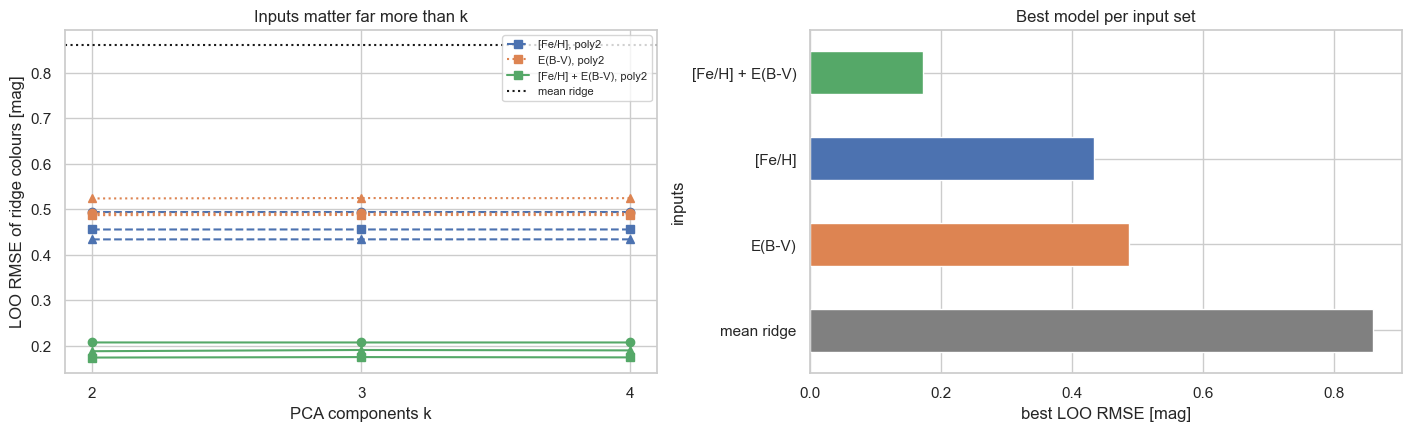

In [9]:
best_inputs = '[Fe/H] + E(B-V)'
sub = res[(res.inputs == best_inputs) & res.model.str.startswith('PCA')]
best_name = sub.loc[sub.RMSE_mag.idxmin(), 'model']
k_best, deg_best = int(best_name.split('PCA')[1][0]), int(best_name.split('poly')[1][0])
print('best model with [Fe/H] + E(B-V):', best_name, round(sub.RMSE_mag.min(), 3), 'mag')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
for iname, ls in zip(INPUTS, ['--', ':', '-']):
    for deg, mk in zip([1, 2, 3], ['o', 's', '^']):
        ys = [res[(res.inputs == iname) & (res.model == f'PCA{k} + poly{deg}')].RMSE_mag.iloc[0] for k in [2, 3, 4]]
        axes[0].plot([2, 3, 4], ys, marker=mk, ls=ls, color=f'C{list(INPUTS).index(iname)}', label=f'{iname}, poly{deg}' if deg == 2 else None)
axes[0].axhline(res.RMSE_mag.iloc[0], color='k', ls=':', label='mean ridge')
axes[0].set_xlabel('PCA components k'); axes[0].set_ylabel('LOO RMSE of ridge colours [mag]')
axes[0].set_xticks([2, 3, 4]); axes[0].legend(fontsize=8); axes[0].set_title('Inputs matter far more than k')
bars = res.loc[res.groupby('inputs').RMSE_mag.idxmin()].set_index('inputs').RMSE_mag
bars.loc['mean ridge'] = res.RMSE_mag.iloc[0]
bars.loc[['mean ridge', 'E(B-V)', '[Fe/H]', '[Fe/H] + E(B-V)']].plot.barh(ax=axes[1], color=['gray', 'C1', 'C0', 'C2'])
axes[1].set_xlabel('best LOO RMSE [mag]'); axes[1].set_title('Best model per input set')
plt.show()

### Does age help on top of that? (only clusters with a Kruijssen age)

In [10]:
has_age = age.notna().to_numpy()
Ys = Yv[has_age]
Xs = {'[Fe/H] + E(B-V)': np.c_[feh, ebv][has_age], '[Fe/H] + E(B-V) + age': np.c_[feh, ebv, age][has_age]}
sub_base = np.array([Ys[np.arange(len(Ys)) != i].mean(0) for i in range(len(Ys))])
out = [dict(inputs='-', model='mean ridge', RMSE_mag=rmse(sub_base, Ys))]
sub_preds = {}
for iname, X in Xs.items():
    for k in [2, 3]:
        for deg in [1, 2]:
            P = loo_forward(lambda: ForwardModel(k, deg), X, Ys)
            out.append(dict(inputs=iname, model=f'PCA{k} + poly{deg}', RMSE_mag=rmse(P, Ys)))
            sub_preds[(iname, f'PCA{k} + poly{deg}')] = P
age_res = pd.DataFrame(out)
print(f'{has_age.sum()} clusters with age')
age_res.sort_values('RMSE_mag').round(3)

25 clusters with age


,inputs,model,RMSE_mag
6,[Fe/H] + E(B-V) + age,PCA2 + poly2,0.131
8,[Fe/H] + E(B-V) + age,PCA3 + poly2,0.132
2,[Fe/H] + E(B-V),PCA2 + poly2,0.142
4,[Fe/H] + E(B-V),PCA3 + poly2,0.143
5,[Fe/H] + E(B-V) + age,PCA2 + poly1,0.158
7,[Fe/H] + E(B-V) + age,PCA3 + poly1,0.158
1,[Fe/H] + E(B-V),PCA2 + poly1,0.188
3,[Fe/H] + E(B-V),PCA3 + poly1,0.188
0,-,mean ridge,0.655


## 3. Does the predicted ridgeline match the observed one?

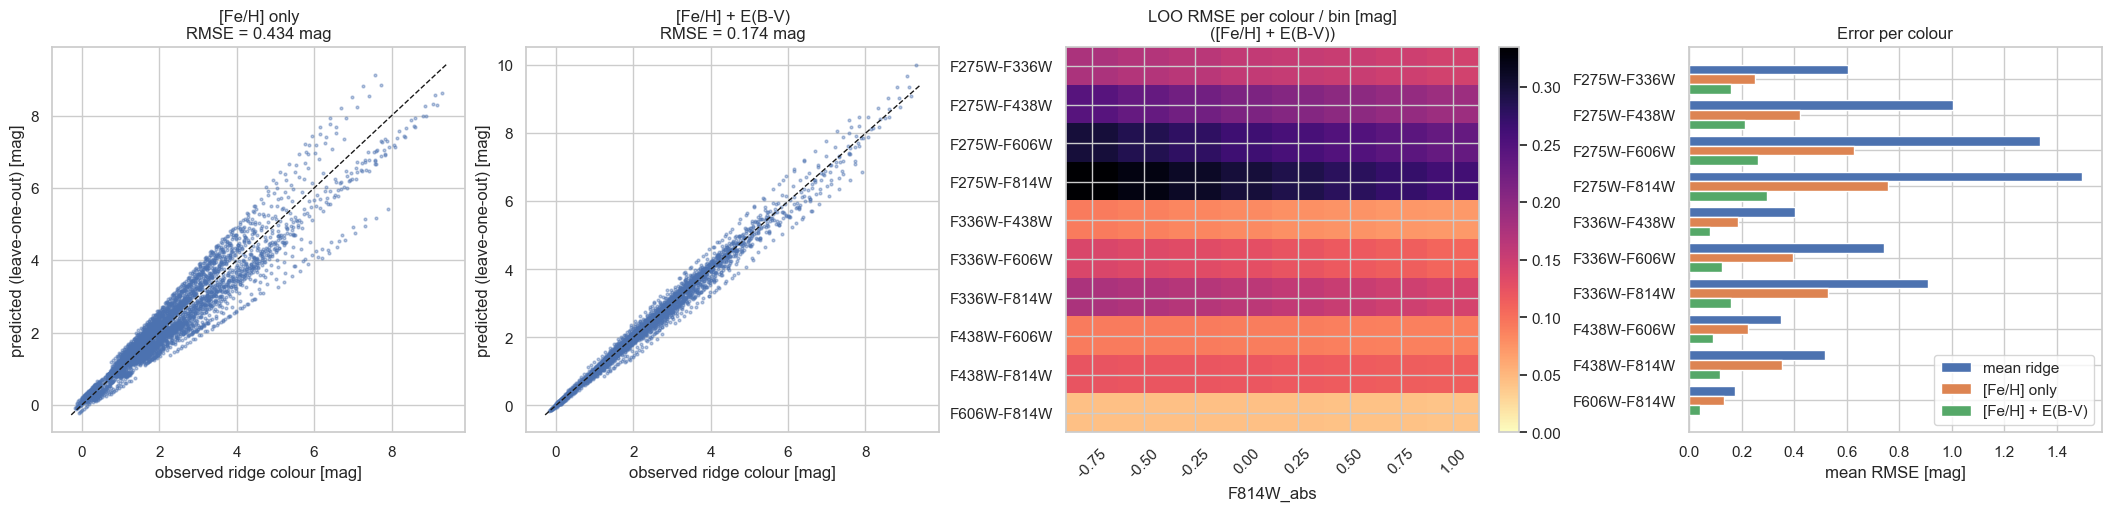

In [11]:
P = loo_preds[(best_inputs, best_name)]
P0 = loo_preds[('[Fe/H]', min([n for (i, n) in loo_preds if i == '[Fe/H]' and n.startswith('PCA')], key=lambda n: rmse(loo_preds[('[Fe/H]', n)], Yv)))]

fig, axes = plt.subplots(1, 4, figsize=(21, 5), constrained_layout=True)
lim = [Yv.min() - .1, Yv.max() + .1]
for ax, PP, t in [(axes[0], P0, '[Fe/H] only'), (axes[1], P, '[Fe/H] + E(B-V)')]:
    ax.scatter(Yv.ravel(), PP.ravel(), s=4, alpha=0.4)
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlabel('observed ridge colour [mag]'); ax.set_ylabel('predicted (leave-one-out) [mag]')
    ax.set_title(f'{t}\nRMSE = {rmse(PP, Yv):.3f} mag')

resid = np.sqrt(((P - Yv) ** 2).mean(0)).reshape(len(COLORS), len(GRID))
im = axes[2].imshow(resid, aspect='auto', cmap='magma_r', vmin=0)
axes[2].set_xticks(range(len(GRID))); axes[2].set_xticklabels([f'{g:.2f}' for g in GRID], rotation=45)
axes[2].set_yticks(range(len(COLORS))); axes[2].set_yticklabels(COLORS)
axes[2].set_xlabel('F814W_abs'); axes[2].set_title('LOO RMSE per colour / bin [mag]\n([Fe/H] + E(B-V))')
fig.colorbar(im, ax=axes[2])

base_c = np.sqrt(((baseline - Yv) ** 2).mean(0)).reshape(len(COLORS), len(GRID)).mean(1)
fe_c = np.sqrt(((P0 - Yv) ** 2).mean(0)).reshape(len(COLORS), len(GRID)).mean(1)
mod_c = resid.mean(1)
yy = np.arange(len(COLORS))
axes[3].barh(yy - 0.27, base_c, height=0.27, label='mean ridge')
axes[3].barh(yy, fe_c, height=0.27, label='[Fe/H] only')
axes[3].barh(yy + 0.27, mod_c, height=0.27, label='[Fe/H] + E(B-V)')
axes[3].set_yticks(yy); axes[3].set_yticklabels(COLORS); axes[3].invert_yaxis()
axes[3].set_xlabel('mean RMSE [mag]'); axes[3].legend(); axes[3].set_title('Error per colour')
plt.show()

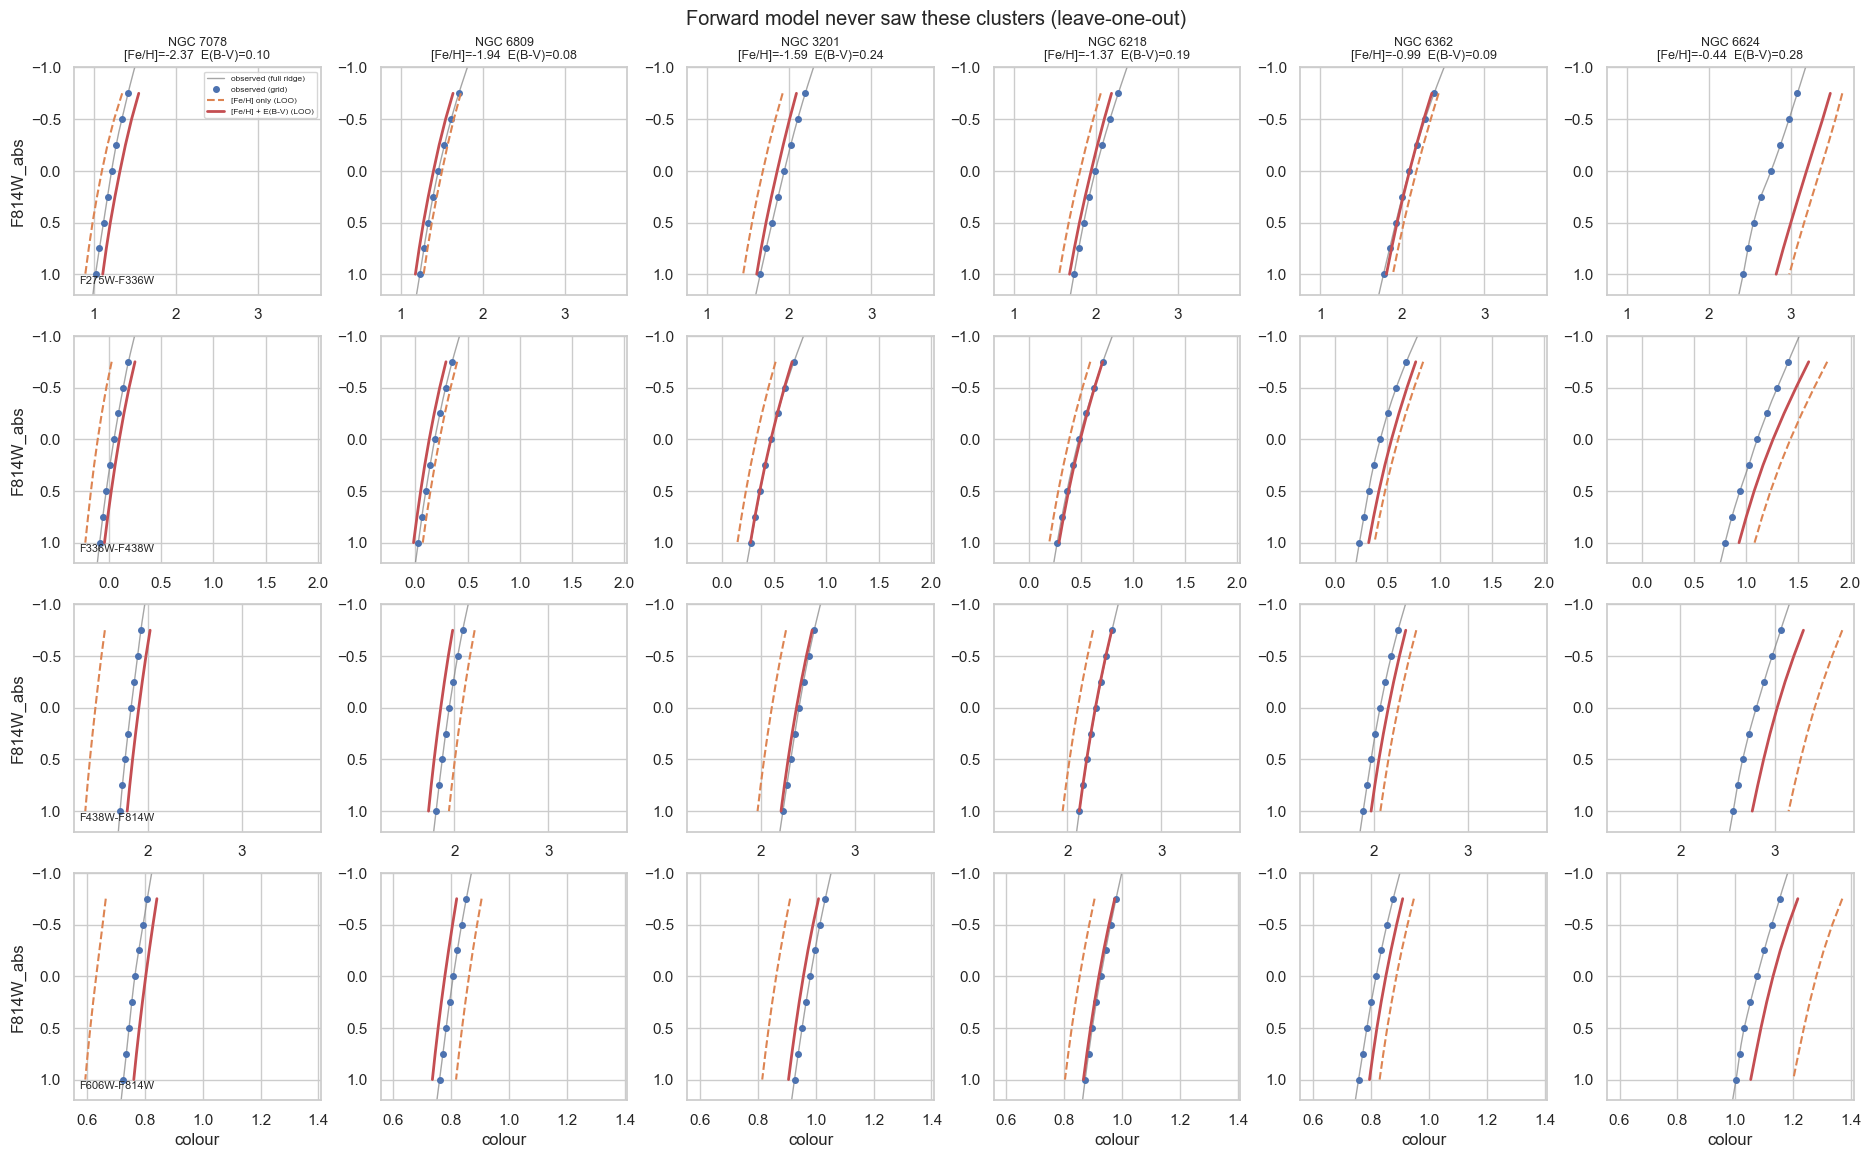

In [12]:
# Observed vs predicted ridges for held-out clusters spanning the metallicity range
order = np.argsort(feh.to_numpy())
pick = order[np.linspace(0, len(order) - 1, 6).astype(int)]
show = ['F275W-F336W', 'F336W-F438W', 'F438W-F814W', 'F606W-F814W']
fv, ev = feh.to_numpy(), ebv.to_numpy()
fig, axes = plt.subplots(len(show), len(pick), figsize=(3.1 * len(pick), 2.8 * len(show)), sharex='row', constrained_layout=True)
for j, i in enumerate(pick):
    for r, c in enumerate(show):
        ci = COLORS.index(c)
        sl = slice(ci * len(GRID), (ci + 1) * len(GRID))
        ax = axes[r, j]
        full = ridges[Y.index[i]]
        ax.plot(full[c], full['F814W_abs'], color='gray', lw=1, alpha=0.7, label='observed (full ridge)')
        ax.plot(Yv[i, sl], GRID, 'o', color='C0', ms=4, label='observed (grid)')
        ax.plot(P0[i, sl], GRID, '--', color='C1', lw=1.5, label='[Fe/H] only (LOO)')
        ax.plot(P[i, sl], GRID, '-', color='C3', lw=2, label='[Fe/H] + E(B-V) (LOO)')
        ax.set_ylim(1.2, -1.0)
        if r == 0: ax.set_title(f'NGC {Y.index[i]}\n[Fe/H]={fv[i]:.2f}  E(B-V)={ev[i]:.2f}', fontsize=9)
        if j == 0: ax.set_ylabel('F814W_abs'); ax.text(0.02, 0.05, c, transform=ax.transAxes, fontsize=8)
        if r == len(show) - 1: ax.set_xlabel('colour')
axes[0, 0].legend(fontsize=6)
fig.suptitle('Forward model never saw these clusters (leave-one-out)', y=1.02)
plt.show()

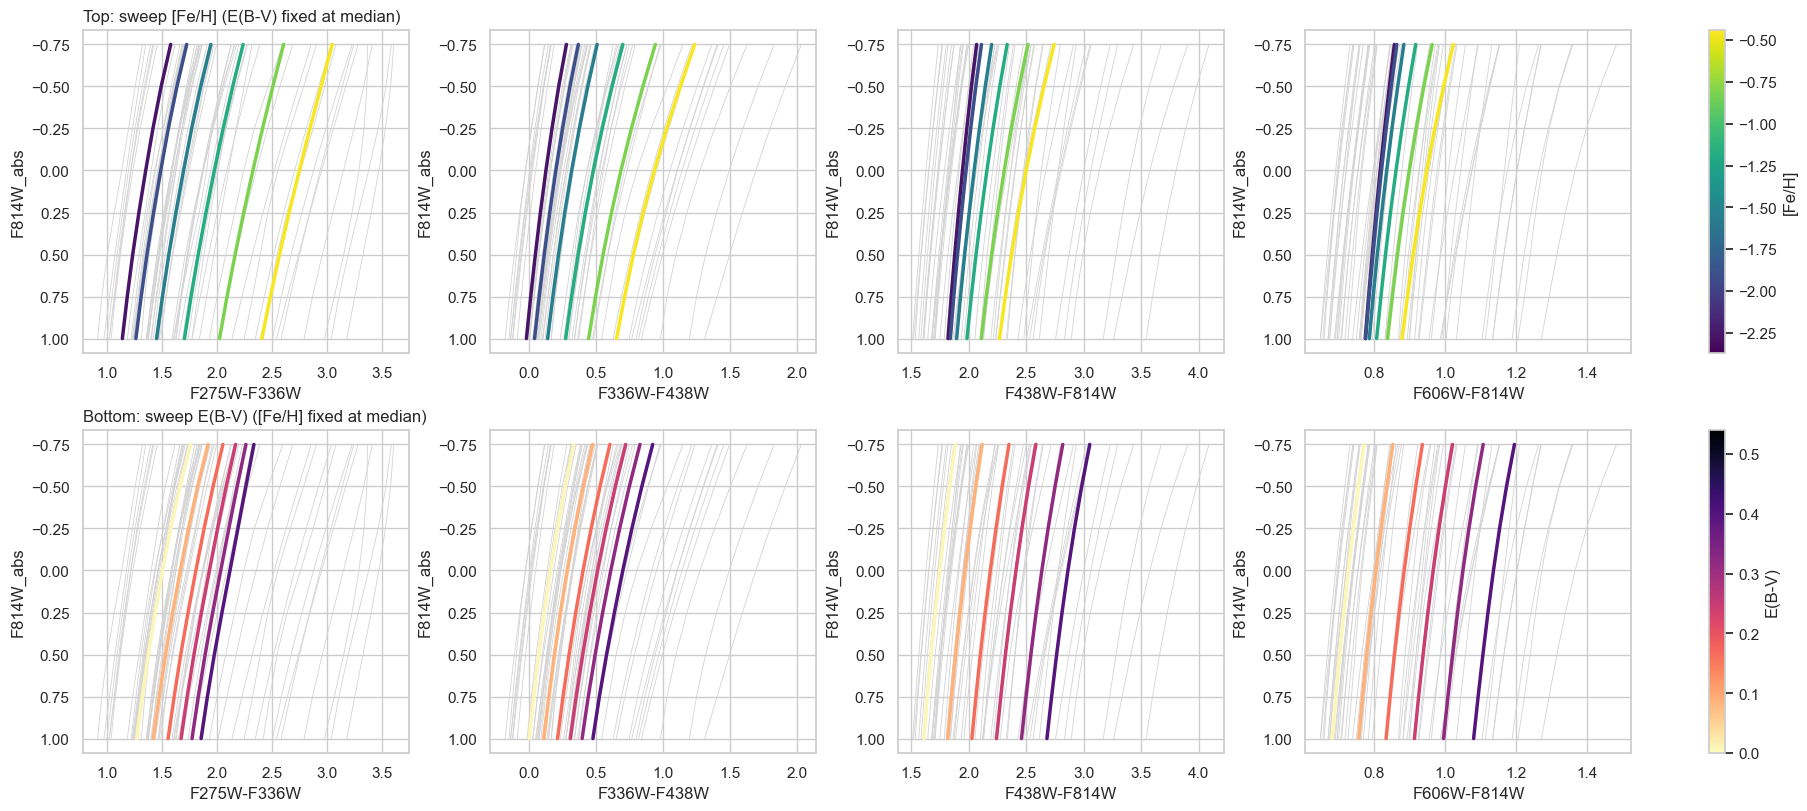

In [13]:
# The model as an emulator: sweep [Fe/H] at fixed E(B-V), and E(B-V) at fixed [Fe/H]
final = ForwardModel(k_best, deg_best).fit(INPUTS[best_inputs], Yv)
fe_sw = np.linspace(np.percentile(fv, 5), np.percentile(fv, 95), 6)
eb_sw = np.linspace(np.percentile(ev, 5), np.percentile(ev, 95), 6)
S1 = final.predict(np.c_[fe_sw, np.full_like(fe_sw, np.median(ev))])
S2 = final.predict(np.c_[np.full_like(eb_sw, np.median(fv)), eb_sw])
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
for r, (S, sw, lab, cmap, rng) in enumerate([(S1, fe_sw, '[Fe/H]', plt.cm.viridis, (fv.min(), fv.max())), (S2, eb_sw, 'E(B-V)', plt.cm.magma_r, (ev.min(), ev.max()))]):
    norm = plt.Normalize(*rng)
    for ax, c in zip(axes[r], show):
        ci = COLORS.index(c); sl = slice(ci * len(GRID), (ci + 1) * len(GRID))
        for i in range(len(Yv)):
            ax.plot(Yv[i, sl], GRID, color='lightgray', lw=0.6)
        for s, row in zip(sw, S):
            ax.plot(row[sl], GRID, color=cmap(norm(s)), lw=2.5)
        ax.invert_yaxis(); ax.set_xlabel(c); ax.set_ylabel('F814W_abs')
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[r], label=lab)
axes[0, 0].set_title('Top: sweep [Fe/H] (E(B-V) fixed at median)', loc='left')
axes[1, 0].set_title('Bottom: sweep E(B-V) ([Fe/H] fixed at median)', loc='left')
plt.show()

## 4. Inverting the forward model

For a held-out cluster: fit the forward model on the other clusters, then find the [Fe/H] whose predicted ridge (at the cluster's known E(B-V)) best matches the observed ridge (chi-square, each ridge value weighted by the model's training scatter). Compared against direct regression from the same ridge values. For the direct regressors, E(B-V) is *not* given (they must cope with it themselves).

predict the mean                         0.542
inverted forward model (E(B-V) given)    0.178
direct ridge                             0.179
direct SVR                               0.143


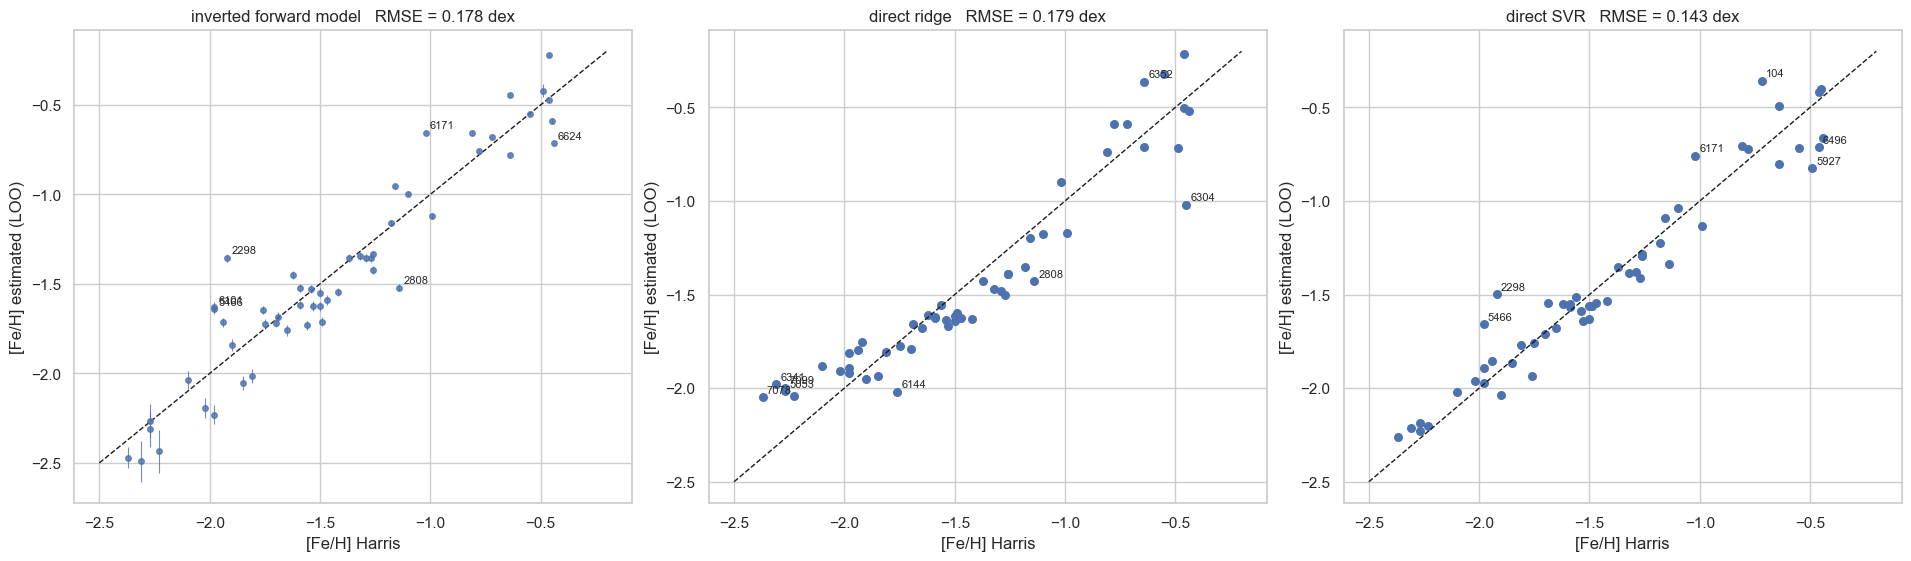

corr(residual, E(B-V)): {'inverted forward model': -0.04, 'direct ridge': -0.19, 'direct SVR': -0.12}


In [14]:
xs = np.linspace(-2.7, 0.0, 541)
idx = np.arange(len(Yv))
inv = np.zeros(len(Yv)); inv_sd = np.zeros(len(Yv))
Xin = INPUTS[best_inputs]
for i in idx:
    tr = idx != i
    m = ForwardModel(k_best, deg_best).fit(Xin[tr], Yv[tr])
    sd = (Yv[tr] - m.predict(Xin[tr])).std(0, ddof=k_best + 1) + 1e-3
    gp = m.predict(np.c_[xs, np.full_like(xs, ev[i])])
    chi2 = (((gp - Yv[i]) / sd) ** 2).sum(1)
    inv[i] = xs[chi2.argmin()]
    red = chi2.min() / (Yv.shape[1] - k_best)
    ok = xs[chi2 <= chi2.min() + max(red, 1.0)]
    inv_sd[i] = (ok.max() - ok.min()) / 2

ridge_m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40)))
svr_m = make_pipeline(StandardScaler(), GridSearchCV(SVR(), {'C': [1, 10, 100], 'gamma': ['scale', 1e-3, 1e-2], 'epsilon': [0.02, 0.1]}, cv=5))
direct = {'direct ridge': np.ravel(cross_val_predict(ridge_m, Yv, fv, cv=LeaveOneOut())),
          'direct SVR': np.ravel(cross_val_predict(svr_m, Yv, fv, cv=LeaveOneOut()))}
summary = {'predict the mean': fv.std(), 'inverted forward model (E(B-V) given)': np.sqrt(np.mean((inv - fv) ** 2))}
summary.update({k: np.sqrt(np.mean((v - fv) ** 2)) for k, v in direct.items()})
print(pd.Series(summary, name='LOO RMSE [dex]').round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
cases = [('inverted forward model', inv, inv_sd), ('direct ridge', direct['direct ridge'], None), ('direct SVR', direct['direct SVR'], None)]
for ax, (t, p, e) in zip(axes, cases):
    if e is not None: ax.errorbar(fv, p, yerr=e, fmt='o', ms=4, lw=0.8, alpha=0.8)
    else: ax.scatter(fv, p, s=30)
    ax.plot([-2.5, -0.2], [-2.5, -0.2], 'k--', lw=1)
    for n, a, b in zip(Y.index, fv, p):
        if abs(a - b) > 0.25: ax.annotate(str(n), (a, b), fontsize=8, xytext=(3, 3), textcoords='offset points')
    ax.set_xlabel('[Fe/H] Harris'); ax.set_ylabel('[Fe/H] estimated (LOO)')
    ax.set_title(f'{t}   RMSE = {np.sqrt(np.mean((p - fv) ** 2)):.3f} dex')
plt.show()

print('corr(residual, E(B-V)):', {t: round(float(np.corrcoef(p - fv, ev)[0, 1]), 2) for t, p, _ in cases})

## 5. Is there leftover signal for age?

Residuals of the [Fe/H] + E(B-V) forward model vs age (clusters with age only).

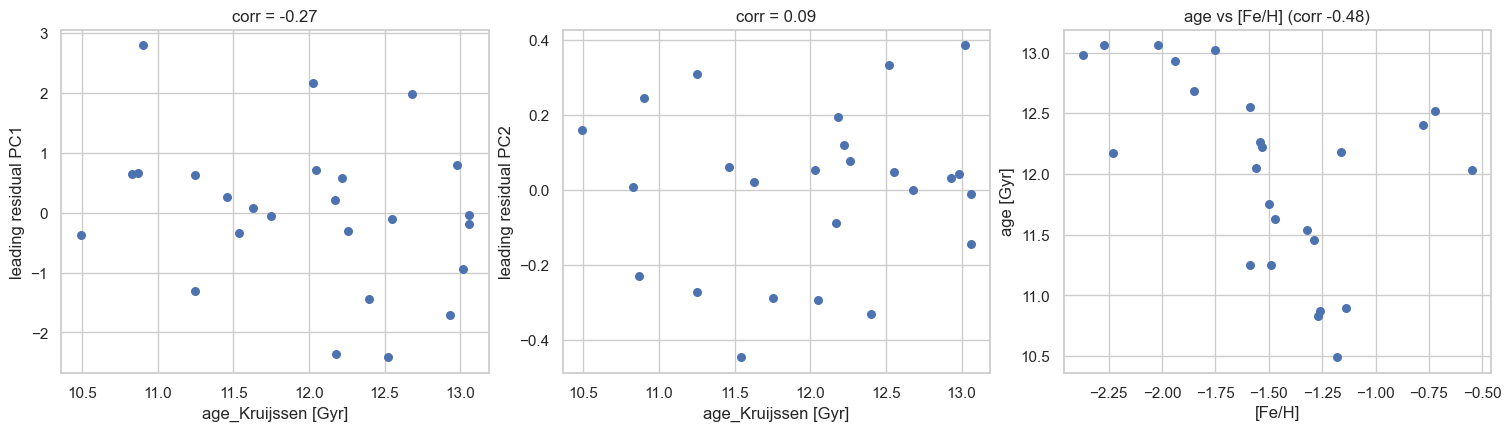

model used: ('[Fe/H] + E(B-V)', 'PCA3 + poly2')


In [15]:
key = ('[Fe/H] + E(B-V)', 'PCA3 + poly2') if ('[Fe/H] + E(B-V)', 'PCA3 + poly2') in sub_preds else list(sub_preds)[0]
resid_sub = sub_preds[key] - Ys
sc = PCA(n_components=2).fit_transform(resid_sub)
a_ = age.to_numpy()[has_age]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for j, ax in enumerate(axes[:2]):
    ax.scatter(a_, sc[:, j], s=30)
    ax.set_xlabel('age_Kruijssen [Gyr]'); ax.set_ylabel(f'leading residual PC{j+1}')
    ax.set_title(f'corr = {np.corrcoef(a_, sc[:, j])[0,1]:.2f}')
axes[2].scatter(fv[has_age], a_, s=30); axes[2].set_xlabel('[Fe/H]'); axes[2].set_ylabel('age [Gyr]')
axes[2].set_title(f'age vs [Fe/H] (corr {np.corrcoef(fv[has_age], a_)[0,1]:.2f})')
plt.show()
print('model used:', key)

## Takeaways / next steps

- Check the tables above: the headline is how much E(B-V) reduces the forward-model error compared with [Fe/H] alone.
- Using E(B-V) from a catalogue is itself approximate; per-cluster differential reddening and the reddening law (R_V) vary. Fitting E(B-V) as a free parameter in the inversion is a natural extension.
- Next: compare against theoretical isochrones (MIST / Dartmouth) with the same E(B-V) and distance.
- Extend to the F438W-axis ridges for fainter/brighter parts of the RGB.